[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/07-interview-prep/03_dsa-classics.ipynb)

*Interview Prep · Notebook 3 of 5*

# Classic Algorithms

The algorithms interviewers ask you to write from memory: sorting, inversions, KMP, Rabin-Karp, union-find, Fenwick and segment trees, shortest paths, knapsack, topological order and designing data structures.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** These are the tools inside the tools. You'll rarely write them at work, but writing them shows you understand trade-offs.

**What interviewers really test here:** Writing them without help, knowing the costs and worst cases, and combining structures in design questions.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Sorting: which, and why *(Basics)*
- [ ] 2. Counting inversions: divide and conquer pays off *(Core)*
- [ ] 3. String searching: KMP and rolling hash *(Core)*
- [ ] 4. Union-find: who's connected? *(Core)*
- [ ] 5. Range queries: Fenwick and segment trees *(Core)*
- [ ] 6. Designing data structures *(Core)*
- [ ] 7. Shortest paths: which algorithm? *(Advanced)*
- [ ] 8. Knapsack: the DP template *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Big-O, in plain numbers

A rough guide: a computer does about 10⁸ simple operations per second in fast languages, and far fewer in Python.



| Input size n | Usually acceptable |
| --- | --- |
| up to 20 | O(2ⁿ), O(n!) |
| up to 500 | O(n³) |
| up to 5,000 | O(n²) |
| up to 10⁶ | O(n log n), O(n) |
| larger | O(log n), O(1) |



So constraints in a question hint at the expected solution. Ask for them.

---
# Part 2: Lessons, step by step

## Lesson 1: Sorting: which, and why

*Level: Basics*

In real code you call `sorted()`. Interviews ask you to write one, to show you understand trade-offs.



**Merge sort** splits in half until single items remain, then merges sorted pieces. Tracing [5, 2, 9, 1]:



```python
[5, 2, 9, 1]
[5, 2]   [9, 1]         split
[2, 5]   [1, 9]         merge each half
[1, 2, 5, 9]            merge: compare the fronts, take the smaller
```



There are log n levels, each doing n work, so it's O(n log n), always. It needs O(n) extra space. It's **stable**, meaning equal items keep their order, because the merge takes from the left on a tie.



**Quick sort** picks a pivot, moves smaller items before it and larger ones after, then recurses. It's usually fastest in practice, and works in place, but a consistently bad pivot gives O(n²). A random or middle pivot makes that unlikely.



**Heap sort** uses O(1) extra space and is O(n log n) always, but it isn't stable, and in practice it's often slower because of poor cache use.



**Counting sort** beats O(n log n) by not comparing. For [3, 1, 2, 1, 0] with values up to 3: counts are 1, 2, 1, 1, so write 0, 1, 1, 2, 3. That's O(n + k), practical only when the range k is small.



|   | Average | Worst | Space | Stable? |
| --- | --- | --- | --- | --- |
| Merge | n log n | n log n | n | yes |
| Quick | n log n | **n²** | log n | no |
| Heap | n log n | n log n | 1 | no |
| Counting | n + k | n + k | k | yes |
| Insertion | n² | n² | 1 | yes |



**Why can't comparison sorts beat n log n?** There are n! possible orders, and each yes/no comparison at best halves the possibilities, which takes about log₂(n!) ≈ n log n comparisons.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

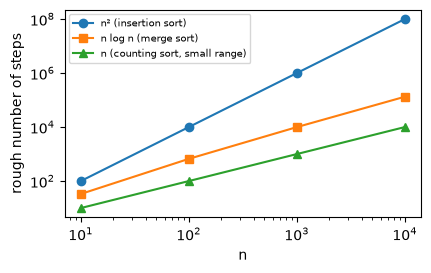

In [2]:
def sort_growth():
    n = np.array([10, 100, 1000, 10000])
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.loglog(n, n ** 2, "o-", label="n² (insertion sort)")
    ax.loglog(n, n * np.log2(n), "s-", label="n log n (merge sort)")
    ax.loglog(n, n, "^-", label="n (counting sort, small range)")
    ax.set_xlabel("n")
    ax.set_ylabel("rough number of steps")
    ax.legend(fontsize=7)


sort_growth()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3), [Q4](#q4), [Q1](#q1). Try one now, or carry on and do them in Part 3.

## Lesson 2: Counting inversions: divide and conquer pays off

*Level: Core*

An inversion is a pair that's out of order. It measures how unsorted a list is, or how much two rankings disagree.



In [2, 4, 1, 3, 5], the pairs are (2, 1), (4, 1) and (4, 3): **3 inversions**. Checking all pairs is O(n²).



**The insight comes during merge sort's merge step.** When an item from the right half goes first, it's smaller than *everything still waiting* in the left half, so each of those forms an inversion, and you can count them all at once:



```python
left = [2, 4]    right = [1, 3]
take 1: 2 items left in the left half → +2 inversions
take 2
take 3: 1 item left in the left half → +1
take 4
```



That's 3 in total, in O(n log n). Many hard problems have this same shape: a brute-force pair count, sped up by sorted halves.

**✏️ Your turn:** you now have what you need for [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 3: String searching: KMP and rolling hash

*Level: Core*

The simple search is O(n·m), because after a mismatch it starts again from the next position. Searching for "aaab" in "aaaaaaa" wastes a lot of work, since you knew those letters were all "a".



**KMP** never moves backward in the text. It first computes, for each prefix of the pattern, the **longest proper prefix that's also a suffix**:



| Pattern | a | b | c | a | b | y |
| --- | --- | --- | --- | --- | --- | --- |
| LPS | 0 | 0 | 0 | 1 | 2 | 0 |



At the second "b" the value is 2, because "ab" is both a prefix and a suffix of "abcab". Suppose you've matched "abcab" and the next letter fails. You already know the text ends in "ab", so you can carry on from position 2 in the pattern, without re-reading anything. That gives O(n + m).



**Rabin-Karp** treats a window of text as a number, and updates it in O(1) as it slides:



```python
new = (old − first_char × base^(m−1)) × base + next_char   (mod a large prime)
```



If the hashes differ, it's definitely not a match. If they're equal, compare the actual text, since different strings can share a hash. It's expected O(n + m), and it extends well to searching for many patterns at once.



In Python, `in` and `str.find` are already well optimised, so only write these when asked. Interviewers are testing whether you can reason about re-using work.

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q16](#q16), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 4: Union-find: who's connected?

*Level: Core*

Suppose friends keep connecting and you need to ask "are these two in the same group?". Re-running a graph search each time is too slow.



**Union-find** stores a forest: each item has a parent, and the root names the group.



```python
find(x):   follow parents up to the root
union(a, b):  point one root at the other
```



Two optimisations make it nearly O(1) per operation:



- **Path compression:** while walking up, point nodes closer to the root.
- **Union by size:** attach the smaller tree under the larger one, so trees stay flat.



**Trace for 4 items:**



| Operation | Result | Groups |
| --- | --- | --- |
| union(0, 1) | True | 3 |
| union(1, 0) | False: already together | 3 |
| union(2, 3) | True | 2 |
| union(1, 2) | True | 1 |



**When to think of it:** counting connected components, detecting a cycle in an undirected graph (a union returning False means a cycle), and Kruskal's minimum spanning tree.

**✏️ Your turn:** you now have what you need for [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 5: Range queries: Fenwick and segment trees

*Level: Core*

You have an array with updates and range questions. The simple options each have a slow side:



| Structure | Update | Range sum |
| --- | --- | --- |
| Plain array | O(1) | O(n) |
| Prefix sums | O(n) | O(1) |
| **Fenwick tree** | O(log n) | O(log n) |
| **Segment tree** | O(log n) | O(log n) |



**Fenwick tree (binary indexed tree).** Each position stores a sum over a range whose length is its lowest set bit, found with `i & -i`:



- To get prefix(7): 7 is 111 in binary. Add tree[7], tree[6], tree[4]: remove the lowest bit each time.
- To update index 5: 101. Touch tree[5], tree[6], tree[8]: add the lowest bit each time.



Every number has at most log n bits, so both are O(log n). The code is very short.



**Segment tree.** A binary tree over the array where each node stores the answer for its range. It's longer to write, but handles any combinable operation, such as min, max or GCD, where prefix tricks can't help.



For [5, 2, 6, 3] with range minimum: leaves 5, 2, 6, 3; parents 2 and 3; root 2. A query for 2..3 reads one node: 3. After setting index 1 to 9, the left parent becomes 5, and the root becomes 3.



These come up less often than hash maps or graphs, so learn the others first. They're typical of competitive programming and of very strong companies.

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q18](#q18), [Q13](#q13). Try one now, or carry on and do them in Part 3.

## Lesson 6: Designing data structures

*Level: Core*

"Design X" questions test whether you can combine simple structures. The method is always this:



1. List the operations and required costs.
2. Ask which single structure gets closest.
3. Add a second structure to fix what it does badly.



| Design | Structures combined | Why |
| --- | --- | --- |
| LRU cache | hash map + doubly linked list | find fast, and reorder fast |
| LFU cache | hash map + one ordered map per frequency | evict the lowest frequency, oldest first |
| Random pick | array + hash map of indices | random index, plus fast lookup |
| Time-based store | hash map of sorted lists | binary search over history |
| Hash map | array of buckets | hash picks a bucket; grow when crowded |



**The swap trick.** To delete from an array in O(1), when order doesn't matter: move the last item into the hole, then pop. Removing 1 from [1, 2, 3]: copy 3 to index 0, pop, giving [3, 2], and update the map entry for 3.



**How a hash map stays fast.** Load factor = items ÷ buckets. When buckets get crowded, double the array and re-insert everything. One resize is expensive, but it's rare enough that the average per insertion stays O(1), which is **amortised** analysis. Worst-case lookup is O(n) if everything collides.



**Tip:** state the required costs out loud, because they usually point straight to the answer. "O(1) lookup" means a hash map. "Sorted, with inserts" means a heap or balanced tree.

**✏️ Your turn:** you now have what you need for [Q19](#q19), [Q6](#q6), [Q7](#q7), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 7: Shortest paths: which algorithm?

*Level: Advanced*

| Situation | Use | Cost |
| --- | --- | --- |
| All edges cost the same | BFS | O(V + E) |
| Non-negative weights | Dijkstra | O(E log V) |
| Negative edges possible | Bellman-Ford | O(V·E) |
| All pairs, small graph | Floyd-Warshall | O(V³) |



**Why does Dijkstra fail with negative edges?** It finalises a node as soon as it's the closest, assuming that no later path can improve it. A negative edge breaks that assumption.



**Bellman-Ford** relaxes every edge, V − 1 times, since a shortest path has at most V − 1 edges. If a further round still improves something, there's a negative cycle.



Edges 0→1 (4), 0→2 (5), 1→2 (−3), 2→3 (2): 0→1 is 4, then 1→2 gives 4 − 3 = 1, which beats the direct 5, then 2→3 gives 3. Distances: 0, 4, 1, 3.



**Floyd-Warshall** is three nested loops: for each middle node k, can going via k improve the route from i to j? The order matters: k must be the outermost loop.



**Topological order, as in Alien Dictionary.** Each adjacent word pair gives one rule, from its first differing letter. "wrt" before "wrf" means t comes before f. Build a graph and repeatedly remove letters with nothing before them. If you get stuck, there's a cycle, so the input is inconsistent. One trap is "abc" before "ab", which is impossible.

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q10](#q10), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 8: Knapsack: the DP template

*Level: Advanced*

Choose items with weights and values to maximise value within a capacity. Greedy by value-per-weight fails: with capacity 7 and items (weight, value) (1, 1), (3, 4), (4, 5), (5, 7), the best ratio is the (5, 7) item, and adding (1, 1) gives value 8. But (3, 4) + (4, 5) gives **9**.



**State:** `dp[room]` is the best value using the items so far within that much room.



**Choice for each item:** skip it, or take it: `dp[room] = max(dp[room], dp[room − w] + v)`.



**Why loop the room downward?** Going upward would let an item use a value that already includes itself, so you'd use it twice. That's exactly the difference between 0/1 knapsack (downward) and unbounded knapsack (upward).



Trying all subsets is O(2ⁿ). The table is O(n·C), where C is the capacity. Note this is "pseudo-polynomial": it depends on the size of the number C, not just the number of items.



Many questions are knapsack in disguise: subset sum, partition into equal sums, target sum, and coin change.

**✏️ Your turn:** you now have what you need for [Q11](#q11). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [3]:
import heapq

from collections import defaultdict, deque, OrderedDict


<a id="q1"></a>
### Q1. Counting Sort

🟢 Warm-up · *Beat O(n log n)*

Sort non-negative integers no larger than k.

**Examples**

- `a = [3, 1, 2, 1, 0], k = 3` → `[0, 1, 1, 2, 3]`

In [ ]:
def counting_sort(a, k):
    """
    Sort non-negative integers no larger than k.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(counting_sort, [
    (([3, 1, 2, 1, 0], 3), [0, 1, 1, 2, 3]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Comparison sort; ignores the small range.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Count each value, then write them out in order.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Comparison sort; ignores the small range.

```python
def counting_sort(a, k):
    return sorted(a)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Count each value, then write them out in order.

```python
def counting_sort(a, k):
    counts = [0] * (k + 1)
    for x in a:
        counts[x] += 1
    out = []
    for value, c in enumerate(counts):
        out += [value] * c
    return out
```

**Cost:** O(n + k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Comparison sort; ignores the small range. That costs O(n log n) time and O(n) space."

"I can do better: Count each value, then write them out in order. That's O(n + k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/counting-sort)

<a id="q2"></a>
### Q2. Merge Sort

🟡 Interview standard · *Divide and conquer*

Sort a list without using built-in sorting.

**Examples**

- `a = [5, 2, 9, 1, 5, 6]` → `[1, 2, 5, 5, 6, 9]`
- `a = []` → `[]`
- `a = [2, 1]` → `[1, 2]`

In [ ]:
def merge_sort(a):
    """
    Sort a list without using built-in sorting.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(merge_sort, [
    (([5, 2, 9, 1, 5, 6],), [1, 2, 5, 5, 6, 9]),
    (([],), []),
    (([2, 1],), [1, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Insertion sort: simple, but quadratic.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Split in half, sort each half, then merge two sorted lists.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Insertion sort: simple, but quadratic.

```python
def merge_sort(a):
    out = list(a)
    for i in range(1, len(out)):
        j = i
        while j > 0 and out[j - 1] > out[j]:
            out[j - 1], out[j] = out[j], out[j - 1]
            j -= 1
    return out
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Split in half, sort each half, then merge two sorted lists.

```python
def merge_sort(a):
    if len(a) <= 1:
        return list(a)
    mid = len(a) // 2
    left, right = merge_sort(a[:mid]), merge_sort(a[mid:])
    out, i, j = [], 0, 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            out.append(left[i])
            i += 1
        else:
            out.append(right[j])
            j += 1
    return out + left[i:] + right[j:]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Insertion sort: simple, but quadratic. That costs O(n²) time and O(1) space."

"I can do better: Split in half, sort each half, then merge two sorted lists. That's O(n log n) time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `a = [5, 2, 9, 1, 5, 6]`

1. merge\_sort() returns [5]
2. merge\_sort() returns [2]
3. merge\_sort() returns [9]
4. merge\_sort() returns [2, 9]
5. merge\_sort() returns [2, 5, 9]
6. merge\_sort() returns [1]
7. merge\_sort() returns [5]
8. merge\_sort() returns [6]
9. merge\_sort() returns [5, 6]
10. merge\_sort() returns [1, 5, 6]

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/merge-sort)

<a id="q3"></a>
### Q3. Quick Sort

🟡 Interview standard · *Partition*

Sort a list using partitioning around a pivot.

**Examples**

- `a = [3, 6, 1, 8, 2, 9, 2]` → `[1, 2, 2, 3, 6, 8, 9]`
- `a = [1]` → `[1]`

In [ ]:
def quick_sort(a):
    """
    Sort a list using partitioning around a pivot.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(quick_sort, [
    (([3, 6, 1, 8, 2, 9, 2],), [1, 2, 2, 3, 6, 8, 9]),
    (([1],), [1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simple version: build new lists around a pivot. Easy to explain, but uses extra memory.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

In place, using Lomuto partition with a middle pivot, swapping it to the end first.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Simple version: build new lists around a pivot. Easy to explain, but uses extra memory.

```python
def quick_sort(a):
    if len(a) <= 1:
        return list(a)
    pivot = a[len(a) // 2]
    less = [x for x in a if x < pivot]
    same = [x for x in a if x == pivot]
    more = [x for x in a if x > pivot]
    return quick_sort(less) + same + quick_sort(more)
```

**Cost:** O(n log n) average time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** In place, using Lomuto partition with a middle pivot, swapping it to the end first.

```python
def quick_sort(a):
    a = list(a)

    def sort(lo, hi):
        if lo >= hi:
            return
        mid = (lo + hi) // 2
        a[mid], a[hi] = a[hi], a[mid]
        store = lo
        for i in range(lo, hi):
            if a[i] < a[hi]:
                a[i], a[store] = a[store], a[i]
                store += 1
        a[store], a[hi] = a[hi], a[store]
        sort(lo, store - 1)
        sort(store + 1, hi)
    sort(0, len(a) - 1)
    return a
```

**Cost:** O(n log n) average time, O(log n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simple version: build new lists around a pivot. Easy to explain, but uses extra memory. That costs O(n log n) average time and O(n) space."

"I can do better: In place, using Lomuto partition with a middle pivot, swapping it to the end first. That's O(n log n) average time and O(log n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `a = [3, 6, 1, 8, 2, 9, 2]`

1. sort() returns None
2. sort() returns None
3. sort() returns None

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/quick-sort)

<a id="q4"></a>
### Q4. Heap Sort

🟡 Interview standard · *Sift down*

Sort using a heap you maintain yourself, in the list.

**Examples**

- `a = [4, 10, 3, 5, 1]` → `[1, 3, 4, 5, 10]`

In [ ]:
def heap_sort(a):
    """
    Sort using a heap you maintain yourself, in the list.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(heap_sort, [
    (([4, 10, 3, 5, 1],), [1, 3, 4, 5, 10]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Use `heapq`: push all, pop all.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Build a max-heap in place, then repeatedly swap the top to the end and sift down.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Use `heapq`: push all, pop all.

```python
def heap_sort(a):
    h = list(a)
    heapq.heapify(h)
    return [heapq.heappop(h) for _ in range(len(h))]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Build a max-heap in place, then repeatedly swap the top to the end and sift down.

```python
def heap_sort(a):
    a = list(a)

    def sift(i, n):
        while 2 * i + 1 < n:
            c = 2 * i + 1
            if c + 1 < n and a[c + 1] > a[c]:
                c += 1
            if a[i] >= a[c]:
                break
            a[i], a[c] = a[c], a[i]
            i = c
    for i in range(len(a) // 2 - 1, -1, -1):
        sift(i, len(a))
    for end in range(len(a) - 1, 0, -1):
        a[0], a[end] = a[end], a[0]
        sift(0, end)
    return a
```

**Cost:** O(n log n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Use `heapq`: push all, pop all. That costs O(n log n) time and O(n) space."

"I can do better: Build a max-heap in place, then repeatedly swap the top to the end and sift down. That's O(n log n) time and O(1) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `a = [4, 10, 3, 5, 1]`

1. sift() returns None
2. sift() returns None
3. sift() returns None
4. sift() returns None
5. sift() returns None
6. sift() returns None
7. heap\_sort() returns [1, 3, 4, 5, 10]

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/heap-sort)

<a id="q5"></a>
### Q5. Union-Find

🟡 Interview standard · *Who's connected?*

Build a class with find(x) and union(a, b), where union returns True if it merged two groups, and count() returns the number of groups.

**Examples**

- `UnionFind(4) → union(0, 1) → union(1, 0) → union(2, 3) → count() → union(1, 2) → count()` → `[True, False, True, 2, True, 1]`

In [ ]:
class UnionFind:
    """
    Build a class with find(x) and union(a, b), where union returns True if it
    merged two groups, and count() returns the number of groups.
    """

    def __init__(self, n):
        pass

    def union(self, a, b):
        pass

    def count(self):
        pass


# ▶ Run this cell to test your answer
check(UnionFind, [
    (((4,), [['union', (0, 1)], ['union', (1, 0)], ['union', (2, 3)], ['count', ()], ['union', (1, 2)], ['count', ()]]), [True, False, True, 2, True, 1]),
], design=True)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Label each item with a group id; a union relabels a whole group.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Parents with path compression and union by size: nearly constant.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Label each item with a group id; a union relabels a whole group.

```python
class UnionFind:
    def __init__(self, n):
        self.group = list(range(n))

    def find(self, x):
        return self.group[x]

    def union(self, a, b):
        ga, gb = self.group[a], self.group[b]
        if ga == gb:
            return False
        self.group = [ga if g == gb else g for g in self.group]
        return True

    def count(self):
        return len(set(self.group))
```

**Cost:** O(n) per union time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Parents with path compression and union by size: nearly constant.

```python
class UnionFind:
    def __init__(self, n):
        self.parent, self.size, self.groups = list(range(n)), [1] * n, n

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a == b:
            return False
        if self.size[a] < self.size[b]:
            a, b = b, a
        self.parent[b] = a
        self.size[a] += self.size[b]
        self.groups -= 1
        return True

    def count(self):
        return self.groups
```

**Cost:** ≈ O(1) per op time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Label each item with a group id; a union relabels a whole group. That costs O(n) per union time and O(n) space."

"I can do better: Parents with path compression and union by size: nearly constant. That's ≈ O(1) per op time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `UnionFind(4) → union(0, 1) → union(1, 0) → union(2, 3) → count() → union(1, 2) → count()`

1. \_\_init\_\_() returns None
2. find() returns 0
3. find() returns 1
4. union() returns True
5. find() returns 0
6. find() returns 0
7. union() returns False
8. find() returns 2
9. find() returns 3
10. union() returns True
11. count() returns 2
12. find() returns 0
13. find() returns 2
14. union() returns True
15. count() returns 1

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/union-find)

<a id="q6"></a>
### Q6. Time-Based Key-Value Store

🟡 Interview standard · *Binary search on history*

Build set(key, value, t) and get(key, t), which returns the value with the largest time ≤ t, or an empty string.

**Examples**

- `TimeMap() → set('a', 'x', 1) → set('a', 'y', 4) → get('a', 3) → get('a', 4) → get('a', 0) → get('b', 1)` → `[None, None, 'x', 'y', '', '']`

In [ ]:
class TimeMap:
    """
    Build set(key, value, t) and get(key, t), which returns the value with the
    largest time ≤ t, or an empty string.
    """

    def __init__(self):
        pass

    def set(self, key, value, t):
        pass

    def get(self, key, t):
        pass


# ▶ Run this cell to test your answer
check(TimeMap, [
    (((), [['set', ('a', 'x', 1)], ['set', ('a', 'y', 4)], ['get', ('a', 3)], ['get', ('a', 4)], ['get', ('a', 0)], ['get', ('b', 1)]]), [None, None, 'x', 'y', '', '']),
], design=True)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan the key's whole history.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Times only increase, so history is sorted: binary search it.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan the key's whole history.

```python
class TimeMap:
    def __init__(self):
        self.data = {}

    def set(self, key, value, t):
        self.data.setdefault(key, []).append((t, value))

    def get(self, key, t):
        best = ""
        for when, value in self.data.get(key, []):
            if when <= t:
                best = value
        return best
```

**Cost:** O(n) per get time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Times only increase, so history is sorted: binary search it.

```python
class TimeMap:
    def __init__(self):
        self.data = defaultdict(list)

    def set(self, key, value, t):
        self.data[key].append((t, value))

    def get(self, key, t):
        history = self.data.get(key, [])
        lo, hi = 0, len(history)
        while lo < hi:
            mid = (lo + hi) // 2
            if history[mid][0] <= t:
                lo = mid + 1
            else:
                hi = mid
        return history[lo - 1][1] if lo else ""
```

**Cost:** O(log n) per get time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan the key's whole history. That costs O(n) per get time and O(n) space."

"I can do better: Times only increase, so history is sorted: binary search it. That's O(log n) per get time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `TimeMap() → set('a', 'x', 1) → set('a', 'y', 4) → get('a', 3) → get('a', 4) → get('a', 0) → get('b', 1)`

1. \_\_init\_\_() returns None
2. set() returns None
3. set() returns None
4. get() returns 'x'
5. get() returns 'y'
6. get() returns ''
7. get() returns ''

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/time-based-key-value-store)

<a id="q7"></a>
### Q7. Design a Hash Map

🟡 Interview standard · *How dict works*

Build put(key, value), get(key) (−1 if missing) and remove(key), without using a dict.

**Examples**

- `MyHashMap() → put(1, 10) → put(2, 20) → get(1) → get(3) → put(2, 30) → get(2) → remove(2) → get(2)` → `[None, None, 10, -1, None, 30, None, -1]`

In [ ]:
class MyHashMap:
    """
    Build put(key, value), get(key) (−1 if missing) and remove(key), without
    using a dict.
    """

    def __init__(self):
        pass

    def put(self, key, value):
        pass

    def get(self, key):
        pass

    def remove(self, key):
        pass


# ▶ Run this cell to test your answer
check(MyHashMap, [
    (((), [['put', (1, 10)], ['put', (2, 20)], ['get', (1,)], ['get', (3,)], ['put', (2, 30)], ['get', (2,)], ['remove', (2,)], ['get', (2,)]]), [None, None, 10, -1, None, 30, None, -1]),
], design=True)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A list of pairs, scanned each time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Buckets indexed by hash, doubling when they get too full.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A list of pairs, scanned each time.

```python
class MyHashMap:
    def __init__(self):
        self.items = []

    def put(self, key, value):
        self.remove(key)
        self.items.append([key, value])

    def get(self, key):
        for k, v in self.items:
            if k == key:
                return v
        return -1

    def remove(self, key):
        self.items = [p for p in self.items if p[0] != key]
```

**Cost:** O(n) per op time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Buckets indexed by hash, doubling when they get too full.

```python
class MyHashMap:
    def __init__(self):
        self.size, self.buckets = 0, [[] for _ in range(8)]

    def _bucket(self, key):
        return self.buckets[hash(key) % len(self.buckets)]

    def put(self, key, value):
        bucket = self._bucket(key)
        for pair in bucket:
            if pair[0] == key:
                pair[1] = value
                return
        bucket.append([key, value])
        self.size += 1
        if self.size > 2 * len(self.buckets):
            old = self.buckets
            self.buckets = [[] for _ in range(2 * len(old))]
            for b in old:
                for k, v in b:
                    self._bucket(k).append([k, v])

    def get(self, key):
        for k, v in self._bucket(key):
            if k == key:
                return v
        return -1

    def remove(self, key):
        bucket = self._bucket(key)
        for i, pair in enumerate(bucket):
            if pair[0] == key:
                bucket.pop(i)
                self.size -= 1
                return
```

**Cost:** O(1) average time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A list of pairs, scanned each time. That costs O(n) per op time and O(n) space."

"I can do better: Buckets indexed by hash, doubling when they get too full. That's O(1) average time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `MyHashMap() → put(1, 10) → put(2, 20) → get(1) → get(3) → put(2, 30) → get(2) → remove(2) → get(2)`

1. \_\_init\_\_() returns None
2. \_bucket() returns []
3. put() returns None
4. \_bucket() returns []
5. put() returns None
6. \_bucket() returns [[1, 10]]
7. get() returns 10
8. \_bucket() returns []
9. get() returns -1
10. \_bucket() returns [[2, 20]]
11. put() returns None
12. \_bucket() returns [[2, 30]]
13. get() returns 30
14. \_bucket() returns [[2, 30]]
15. remove() returns None

*…and so on.*

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/design-a-hash-map)

<a id="q8"></a>
### Q8. Insert, Delete, Random in O(1)

🟡 Interview standard · *List plus dictionary*

Build insert(x) and remove(x), each returning whether it changed anything, and contains(x). (A real get\_random would use random.choice on the list.)

**Examples**

- `RandomizedSet() → insert(1) → insert(1) → insert(2) → remove(1) → contains(1) → remove(5) → contains(2)` → `[True, False, True, True, False, False, True]`

In [ ]:
class RandomizedSet:
    """
    Build insert(x) and remove(x), each returning whether it changed anything,
    and contains(x). (A real get_random would use random.choice on the list.)
    """

    def __init__(self):
        pass

    def insert(self, x):
        pass

    def remove(self, x):
        pass

    def contains(self, x):
        pass


# ▶ Run this cell to test your answer
check(RandomizedSet, [
    (((), [['insert', (1,)], ['insert', (1,)], ['insert', (2,)], ['remove', (1,)], ['contains', (1,)], ['remove', (5,)], ['contains', (2,)]]), [True, False, True, True, False, False, True]),
], design=True)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A list alone: fast random choice, slow membership and removal.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary from value to index. To remove, swap with the last item, then pop.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A list alone: fast random choice, slow membership and removal.

```python
class RandomizedSet:
    def __init__(self):
        self.items = []

    def insert(self, x):
        if x in self.items:
            return False
        self.items.append(x)
        return True

    def remove(self, x):
        if x not in self.items:
            return False
        self.items.remove(x)
        return True

    def contains(self, x):
        return x in self.items
```

**Cost:** O(n) per op time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary from value to index. To remove, swap with the last item, then pop.

```python
class RandomizedSet:
    def __init__(self):
        self.items, self.where = [], {}

    def insert(self, x):
        if x in self.where:
            return False
        self.where[x] = len(self.items)
        self.items.append(x)
        return True

    def remove(self, x):
        if x not in self.where:
            return False
        i, last = self.where.pop(x), self.items.pop()
        if i < len(self.items):
            self.items[i] = last
            self.where[last] = i
        return True

    def contains(self, x):
        return x in self.where
```

**Cost:** O(1) per op time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A list alone: fast random choice, slow membership and removal. That costs O(n) per op time and O(n) space."

"I can do better: A dictionary from value to index. To remove, swap with the last item, then pop. That's O(1) per op time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `RandomizedSet() → insert(1) → insert(1) → insert(2) → remove(1) → contains(1) → remove(5) → contains(2)`

1. \_\_init\_\_() returns None
2. insert() returns True
3. insert() returns False
4. insert() returns True
5. remove() returns True
6. contains() returns False
7. remove() returns False
8. contains() returns True

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/insert-delete-random-in-o-1)

<a id="q9"></a>
### Q9. Bellman-Ford

🟡 Interview standard · *Negative edges*

Return shortest distances from source 0 through edges (u, v, w), with None for unreachable. If a negative cycle is reachable, return 'negative cycle'.

**Examples**

- `n = 4, edges = [(0, 1, 4), (0, 2, 5), (1, 2, -3), (2, 3, 2)]` → `[0, 4, 1, 3]`
- `n = 3, edges = [(0, 1, 1), (1, 2, -2), (2, 1, 1)]` → `'negative cycle'`
- `n = 3, edges = [(1, 2, 1)]` → `[0, None, None]`

In [ ]:
def bellman_ford(n, edges):
    """
    Return shortest distances from source 0 through edges (u, v, w), with None
    for unreachable. If a negative cycle is reachable, return 'negative cycle'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bellman_ford, [
    ((4, [(0, 1, 4), (0, 2, 5), (1, 2, -3), (2, 3, 2)]), [0, 4, 1, 3]),
    ((3, [(0, 1, 1), (1, 2, -2), (2, 1, 1)]), 'negative cycle'),
    ((3, [(1, 2, 1)]), [0, None, None]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Relax all edges V times; a change on the last round means a negative cycle.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The same, stopping early when a round changes nothing.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Relax all edges V times; a change on the last round means a negative cycle.

```python
def bellman_ford(n, edges):
    inf = float("inf")
    d = [inf] * n
    d[0] = 0
    for _ in range(n - 1):
        for u, v, w in edges:
            if d[u] + w < d[v]:
                d[v] = d[u] + w
    for u, v, w in edges:
        if d[u] + w < d[v]:
            return "negative cycle"
    return [None if x == inf else x for x in d]
```

**Cost:** O(V·E) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The same, stopping early when a round changes nothing.

```python
def bellman_ford(n, edges):
    inf = float("inf")
    d = [inf] * n
    d[0] = 0
    for _ in range(n):
        changed = False
        for u, v, w in edges:
            if d[u] + w < d[v]:
                d[v] = d[u] + w
                changed = True
        if not changed:
            return [None if x == inf else x for x in d]
    return "negative cycle"
```

**Cost:** O(V·E), often less time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Relax all edges V times; a change on the last round means a negative cycle. That costs O(V·E) time and O(V) space."

"I can do better: The same, stopping early when a round changes nothing. That's O(V·E), often less time and O(V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/bellman-ford)

<a id="q10"></a>
### Q10. Floyd-Warshall

🟡 Interview standard · *All pairs*

Return the n × n table of shortest distances for directed edges (u, v, w), with None for unreachable.

**Examples**

- `n = 3, edges = [(0, 1, 4), (1, 2, 1), (0, 2, 7)]` → `[[0, 4, 5], [None, 0, 1], [None, None, 0]]`

In [ ]:
def all_pairs(n, edges):
    """
    Return the n × n table of shortest distances for directed edges (u, v, w),
    with None for unreachable.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(all_pairs, [
    ((3, [(0, 1, 4), (1, 2, 1), (0, 2, 7)]), [[0, 4, 5], [None, 0, 1], [None, None, 0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Run Bellman-Ford from each start.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

For each middle node k, try improving every path via k.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Run Bellman-Ford from each start.

```python
def all_pairs(n, edges):
    out = []
    for s in range(n):
        d = [float("inf")] * n
        d[s] = 0
        for _ in range(n - 1):
            for u, v, w in edges:
                d[v] = min(d[v], d[u] + w)
        out.append([None if x == float("inf") else x for x in d])
    return out
```

**Cost:** O(V²·E) time, O(V²) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** For each middle node k, try improving every path via k.

```python
def all_pairs(n, edges):
    inf = float("inf")
    d = [[0 if i == j else inf for j in range(n)] for i in range(n)]
    for u, v, w in edges:
        d[u][v] = min(d[u][v], w)
    for k in range(n):
        for i in range(n):
            for j in range(n):
                d[i][j] = min(d[i][j], d[i][k] + d[k][j])
    return [[None if x == inf else x for x in row] for row in d]
```

**Cost:** O(V³) time, O(V²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Run Bellman-Ford from each start. That costs O(V²·E) time and O(V²) space."

"I can do better: For each middle node k, try improving every path via k. That's O(V³) time and O(V²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/floyd-warshall)

<a id="q11"></a>
### Q11. 0/1 Knapsack

🟡 Interview standard · *The DP you must know*

Return the maximum value that fits in the capacity, using each item once.

**Examples**

- `weights = [1, 3, 4, 5], values = [1, 4, 5, 7], capacity = 7` → `9`
- `weights = [2], values = [3], capacity = 1` → `0`

In [ ]:
def knapsack(weights, values, capacity):
    """
    Return the maximum value that fits in the capacity, using each item once.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(knapsack, [
    (([1, 3, 4, 5], [1, 4, 5, 7], 7), 9),
    (([2], [3], 1), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Recursion: take or skip each item.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One DP row, filled right to left, so each item is used once.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Recursion: take or skip each item.

```python
def knapsack(weights, values, capacity):
    def best(i, room):
        if i == len(weights):
            return 0
        skip = best(i + 1, room)
        if weights[i] > room:
            return skip
        return max(skip, values[i] + best(i + 1, room - weights[i]))
    return best(0, capacity)
```

**Cost:** O(2ⁿ) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One DP row, filled right to left, so each item is used once.

```python
def knapsack(weights, values, capacity):
    dp = [0] * (capacity + 1)
    for w, v in zip(weights, values):
        for room in range(capacity, w - 1, -1):
            dp[room] = max(dp[room], dp[room - w] + v)
    return dp[capacity]
```

**Cost:** O(n·C) time, O(C) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Recursion: take or skip each item. That costs O(2ⁿ) time and O(n) space."

"I can do better: One DP row, filled right to left, so each item is used once. That's O(n·C) time and O(C) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/0-1-knapsack)

<a id="q12"></a>
### Q12. Longest Common Substring

🟡 Interview standard · *Contiguous, unlike subsequence*

Return the length of the longest substring appearing in both strings.

**Examples**

- `a = 'abcdxyz', b = 'xyzabcd'` → `4`
- `a = 'abc', b = 'def'` → `0`

In [ ]:
def common_substring(a, b):
    """
    Return the length of the longest substring appearing in both strings.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(common_substring, [
    (('abcdxyz', 'xyzabcd'), 4),
    (('abc', 'def'), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Try every start pair and extend.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

DP: dp[j] = dp\_prev[j−1] + 1 if the characters match, else 0.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Try every start pair and extend.

```python
def common_substring(a, b):
    best = 0
    for i in range(len(a)):
        for j in range(len(b)):
            k = 0
            while i + k < len(a) and j + k < len(b) and a[i + k] == b[j + k]:
                k += 1
            best = max(best, k)
    return best
```

**Cost:** O(n·m·min) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** DP: dp[j] = dp\_prev[j−1] + 1 if the characters match, else 0.

```python
def common_substring(a, b):
    prev, best = [0] * (len(b) + 1), 0
    for ch in a:
        cur = [0] * (len(b) + 1)
        for j in range(1, len(b) + 1):
            if ch == b[j - 1]:
                cur[j] = prev[j - 1] + 1
                best = max(best, cur[j])
        prev = cur
    return best
```

**Cost:** O(n·m) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Try every start pair and extend. That costs O(n·m·min) time and O(1) space."

"I can do better: DP: dp[j] = dp\_prev[j−1] + 1 if the characters match, else 0. That's O(n·m) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/longest-common-substring)

<a id="q13"></a>
### Q13. Weighted Random Pick

🟡 Interview standard · *Prefix sums + binary search*

Given weights and a number r in [0, total), return the chosen index. (Real code would draw r at random.)

**Examples**

- `weights = [1, 3, 2], r = 0` → `0`
- `weights = [1, 3, 2], r = 3.5` → `1`
- `weights = [1, 3, 2], r = 5.9` → `2`

In [ ]:
def weighted_pick(weights, r):
    """
    Given weights and a number r in [0, total), return the chosen index. (Real
    code would draw r at random.)
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(weighted_pick, [
    (([1, 3, 2], 0), 0),
    (([1, 3, 2], 3.5), 1),
    (([1, 3, 2], 5.9), 2),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Walk the weights, subtracting.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Precompute prefix sums, then binary search.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Walk the weights, subtracting.

```python
def weighted_pick(weights, r):
    for i, w in enumerate(weights):
        if r < w:
            return i
        r -= w
    return len(weights) - 1
```

**Cost:** O(n) per pick time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Precompute prefix sums, then binary search.

```python
def weighted_pick(weights, r):
    import bisect
    import itertools
    return bisect.bisect_right(list(itertools.accumulate(weights)), r)
```

**Cost:** O(log n) per pick time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Walk the weights, subtracting. That costs O(n) per pick time and O(1) space."

"I can do better: Precompute prefix sums, then binary search. That's O(log n) per pick time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/weighted-random-pick)

<a id="q14"></a>
### Q14. Count Inversions

🔴 Stretch · *Merge sort's bonus*

Count pairs i &lt; j with a[i] &gt; a[j].

**Examples**

- `a = [2, 4, 1, 3, 5]` → `3`
- `a = [5, 4, 3, 2, 1]` → `10`
- `a = [1, 2]` → `0`

In [ ]:
def inversions(a):
    """
    Count pairs i < j with a[i] > a[j].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(inversions, [
    (([2, 4, 1, 3, 5],), 3),
    (([5, 4, 3, 2, 1],), 10),
    (([1, 2],), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check every pair.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

During merging, when a right element goes first, it forms an inversion with everything left in the left half.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Check every pair.

```python
def inversions(a):
    return sum(1 for i in range(len(a)) for j in range(i + 1, len(a)) if a[i] > a[j])
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** During merging, when a right element goes first, it forms an inversion with everything left in the left half.

```python
def inversions(a):
    def solve(x):
        if len(x) <= 1:
            return x, 0
        left, lc = solve(x[:len(x) // 2])
        right, rc = solve(x[len(x) // 2:])
        out, i, j, count = [], 0, 0, lc + rc
        while i < len(left) and j < len(right):
            if left[i] <= right[j]:
                out.append(left[i])
                i += 1
            else:
                count += len(left) - i
                out.append(right[j])
                j += 1
        return out + left[i:] + right[j:], count
    return solve(a)[1]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check every pair. That costs O(n²) time and O(1) space."

"I can do better: During merging, when a right element goes first, it forms an inversion with everything left in the left half. That's O(n log n) time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `a = [2, 4, 1, 3, 5]`

1. solve() returns ([2], 0)
2. solve() returns ([4], 0)
3. solve() returns ([2, 4], 0)
4. solve() returns ([1], 0)
5. solve() returns ([3], 0)
6. solve() returns ([5], 0)
7. solve() returns ([3, 5], 0)
8. solve() returns ([1, 3, 5], 0)
9. solve() returns ([1, 2, 3, 4, 5], 3)
10. inversions() returns 3

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/count-inversions)

<a id="q15"></a>
### Q15. Substring Search With KMP

🔴 Stretch · *Never look back*

Return the first index of pattern in text, or −1, without built-in find.

**Examples**

- `text = 'abxabcabcaby', pattern = 'abcaby'` → `6`
- `text = 'aaaa', pattern = 'b'` → `-1`
- `text = 'abc', pattern = ''` → `0`

In [ ]:
def find_first(text, pattern):
    """
    Return the first index of pattern in text, or −1, without built-in find.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(find_first, [
    (('abxabcabcaby', 'abcaby'), 6),
    (('aaaa', 'b'), -1),
    (('abc', ''), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Try every start position.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Pre-compute the longest prefix that's also a suffix, so a mismatch skips what's already matched.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Try every start position.

```python
def find_first(text, pattern):
    for i in range(len(text) - len(pattern) + 1):
        j = 0
        while j < len(pattern) and text[i + j] == pattern[j]:
            j += 1
        if j == len(pattern):
            return i
    return -1
```

**Cost:** O(n·m) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Pre-compute the longest prefix that's also a suffix, so a mismatch skips what's already matched.

```python
def find_first(text, pattern):
    if not pattern:
        return 0
    lps = [0] * len(pattern)
    k = 0
    for i in range(1, len(pattern)):
        while k and pattern[i] != pattern[k]:
            k = lps[k - 1]
        if pattern[i] == pattern[k]:
            k += 1
        lps[i] = k
    k = 0
    for i, ch in enumerate(text):
        while k and ch != pattern[k]:
            k = lps[k - 1]
        if ch == pattern[k]:
            k += 1
        if k == len(pattern):
            return i - k + 1
    return -1
```

**Cost:** O(n + m) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Try every start position. That costs O(n·m) time and O(1) space."

"I can do better: Pre-compute the longest prefix that's also a suffix, so a mismatch skips what's already matched. That's O(n + m) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/substring-search-with-kmp)

<a id="q16"></a>
### Q16. All Matches With a Rolling Hash

🔴 Stretch · *Rabin-Karp*

Return all start positions of pattern in text.

**Examples**

- `text = 'abababa', pattern = 'aba'` → `[0, 2, 4]`
- `text = 'abc', pattern = 'd'` → `[]`

In [ ]:
def all_matches(text, pattern):
    """
    Return all start positions of pattern in text.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(all_matches, [
    (('abababa', 'aba'), [0, 2, 4]),
    (('abc', 'd'), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compare a slice at every position.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Update a window's hash in O(1); compare the actual text only when hashes match.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compare a slice at every position.

```python
def all_matches(text, pattern):
    m = len(pattern)
    return [i for i in range(len(text) - m + 1) if text[i:i + m] == pattern]
```

**Cost:** O(n·m) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Update a window's hash in O(1); compare the actual text only when hashes match.

```python
def all_matches(text, pattern):
    base, mod = 256, 1_000_000_007
    m, n = len(pattern), len(text)
    if m > n:
        return []
    top = pow(base, m - 1, mod)
    p = w = 0
    for i in range(m):
        p = (p * base + ord(pattern[i])) % mod
        w = (w * base + ord(text[i])) % mod
    out = []
    for i in range(n - m + 1):
        if w == p and text[i:i + m] == pattern:
            out.append(i)
        if i + m < n:
            w = ((w - ord(text[i]) * top) * base + ord(text[i + m])) % mod
    return out
```

**Cost:** O(n + m) expected time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compare a slice at every position. That costs O(n·m) time and O(m) space."

"I can do better: Update a window's hash in O(1); compare the actual text only when hashes match. That's O(n + m) expected time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/all-matches-with-a-rolling-hash)

<a id="q17"></a>
### Q17. Fenwick Tree

🔴 Stretch · *Prefix sums with updates*

Build a class with add(i, delta) and prefix(i), the sum of the first i values.

**Examples**

- `Fenwick(5) → add(0, 3) → add(2, 4) → prefix(1) → prefix(3) → add(1, 2) → prefix(3)` → `[None, None, 3, 7, None, 9]`

In [ ]:
class Fenwick:
    """
    Build a class with add(i, delta) and prefix(i), the sum of the first i
    values.
    """

    def __init__(self, n):
        pass

    def add(self, i, delta):
        pass

    def prefix(self, i):
        pass


# ▶ Run this cell to test your answer
check(Fenwick, [
    (((5,), [['add', (0, 3)], ['add', (2, 4)], ['prefix', (1,)], ['prefix', (3,)], ['add', (1, 2)], ['prefix', (3,)]]), [None, None, 3, 7, None, 9]),
], design=True)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A plain array: fast add, slow prefix.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Each index covers a range given by its lowest set bit, i & −i.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A plain array: fast add, slow prefix.

```python
class Fenwick:
    def __init__(self, n):
        self.a = [0] * n

    def add(self, i, delta):
        self.a[i] += delta

    def prefix(self, i):
        return sum(self.a[:i])
```

**Cost:** O(n) per prefix time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Each index covers a range given by its lowest set bit, i & −i.

```python
class Fenwick:
    def __init__(self, n):
        self.tree = [0] * (n + 1)

    def add(self, i, delta):
        i += 1
        while i < len(self.tree):
            self.tree[i] += delta
            i += i & -i

    def prefix(self, i):
        total = 0
        while i > 0:
            total += self.tree[i]
            i -= i & -i
        return total
```

**Cost:** O(log n) per op time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A plain array: fast add, slow prefix. That costs O(n) per prefix time and O(n) space."

"I can do better: Each index covers a range given by its lowest set bit, i & −i. That's O(log n) per op time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `Fenwick(5) → add(0, 3) → add(2, 4) → prefix(1) → prefix(3) → add(1, 2) → prefix(3)`

1. \_\_init\_\_() returns None
2. add() returns None
3. add() returns None
4. prefix() returns 3
5. prefix() returns 7
6. add() returns None
7. prefix() returns 9

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/fenwick-tree)

<a id="q18"></a>
### Q18. Segment Tree: Range Minimum

🔴 Stretch · *Any range, with updates*

Build a class from a list, with update(i, value) and query(lo, hi) for the minimum of a[lo..hi] inclusive.

**Examples**

- `RangeMin([5, 2, 6, 3]) → query(0, 3) → query(2, 3) → update(1, 9) → query(0, 1)` → `[2, 3, None, 5]`

In [ ]:
class RangeMin:
    """
    Build a class from a list, with update(i, value) and query(lo, hi) for the
    minimum of a[lo..hi] inclusive.
    """

    def __init__(self, a):
        pass

    def query(self, lo, hi):
        pass

    def update(self, i, value):
        pass


# ▶ Run this cell to test your answer
check(RangeMin, [
    ((([5, 2, 6, 3],), [['query', (0, 3)], ['query', (2, 3)], ['update', (1, 9)], ['query', (0, 1)]]), [2, 3, None, 5]),
], design=True)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan the range on each query.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A binary tree stored in an array, where each node holds the minimum of its range.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan the range on each query.

```python
class RangeMin:
    def __init__(self, a):
        self.a = list(a)

    def update(self, i, value):
        self.a[i] = value

    def query(self, lo, hi):
        return min(self.a[lo:hi + 1])
```

**Cost:** O(n) per query time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A binary tree stored in an array, where each node holds the minimum of its range.

```python
class RangeMin:
    def __init__(self, a):
        self.n = len(a)
        self.t = [0] * self.n + list(a)
        for i in range(self.n - 1, 0, -1):
            self.t[i] = min(self.t[2 * i], self.t[2 * i + 1])

    def update(self, i, value):
        i += self.n
        self.t[i] = value
        while i > 1:
            i //= 2
            self.t[i] = min(self.t[2 * i], self.t[2 * i + 1])

    def query(self, lo, hi):
        lo += self.n
        hi += self.n + 1
        best = float("inf")
        while lo < hi:
            if lo & 1:
                best = min(best, self.t[lo])
                lo += 1
            if hi & 1:
                hi -= 1
                best = min(best, self.t[hi])
            lo //= 2
            hi //= 2
        return best
```

**Cost:** O(log n) per op time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan the range on each query. That costs O(n) per query time and O(n) space."

"I can do better: A binary tree stored in an array, where each node holds the minimum of its range. That's O(log n) per op time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `RangeMin([5, 2, 6, 3]) → query(0, 3) → query(2, 3) → update(1, 9) → query(0, 1)`

1. \_\_init\_\_() returns None
2. query() returns 2
3. query() returns 3
4. update() returns None
5. query() returns 5

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/segment-tree-range-minimum)

<a id="q19"></a>
### Q19. LFU Cache

🔴 Stretch · *A harder LRU*

Build get(key) and put(key, value) with a capacity. Evict the least frequently used key; ties go to the least recently used.

**Examples**

- `LFUCache(2) → put(1, 1) → put(2, 2) → get(1) → put(3, 3) → get(2) → get(3) → get(1)` → `[None, None, 1, None, -1, 3, 1]`

In [ ]:
class LFUCache:
    """
    Build get(key) and put(key, value) with a capacity. Evict the least
    frequently used key; ties go to the least recently used.
    """

    def __init__(self, capacity):
        pass

    def put(self, key, value):
        pass

    def get(self, key):
        pass


# ▶ Run this cell to test your answer
check(LFUCache, [
    (((2,), [['put', (1, 1)], ['put', (2, 2)], ['get', (1,)], ['put', (3, 3)], ['get', (2,)], ['get', (3,)], ['get', (1,)]]), [None, None, 1, None, -1, 3, 1]),
], design=True)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan all keys to find the eviction.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A group of ordered dictionaries per frequency, plus the current minimum frequency.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan all keys to find the eviction.

```python
class LFUCache:
    def __init__(self, capacity):
        self.capacity, self.time = capacity, 0
        self.data = {}

    def get(self, key):
        if key not in self.data:
            return -1
        value, freq, _ = self.data[key]
        self.time += 1
        self.data[key] = (value, freq + 1, self.time)
        return value

    def put(self, key, value):
        self.time += 1
        if key in self.data:
            self.data[key] = (value, self.data[key][1] + 1, self.time)
            return None
        if len(self.data) == self.capacity:
            del self.data[min(self.data, key=lambda k: self.data[k][1:])]
        self.data[key] = (value, 1, self.time)
        return None
```

**Cost:** O(c) per eviction time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A group of ordered dictionaries per frequency, plus the current minimum frequency.

```python
class LFUCache:
    def __init__(self, capacity):
        self.capacity, self.low = capacity, 0
        self.values, self.freq = {}, {}
        self.groups = defaultdict(OrderedDict)

    def _bump(self, key):
        f = self.freq[key]
        del self.groups[f][key]
        if not self.groups[f] and self.low == f:
            self.low = f + 1
        self.freq[key] = f + 1
        self.groups[f + 1][key] = None

    def get(self, key):
        if key not in self.values:
            return -1
        self._bump(key)
        return self.values[key]

    def put(self, key, value):
        if key in self.values:
            self.values[key] = value
            self._bump(key)
            return None
        if len(self.values) == self.capacity:
            old, _ = self.groups[self.low].popitem(last=False)
            del self.values[old], self.freq[old]
        self.values[key], self.freq[key], self.low = value, 1, 1
        self.groups[1][key] = None
        return None
```

**Cost:** O(1) per op time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan all keys to find the eviction. That costs O(c) per eviction time and O(c) space."

"I can do better: A group of ordered dictionaries per frequency, plus the current minimum frequency. That's O(1) per op time and O(c) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `LFUCache(2) → put(1, 1) → put(2, 2) → get(1) → put(3, 3) → get(2) → get(3) → get(1)`

1. \_\_init\_\_() returns None
2. put() returns None
3. put() returns None
4. \_bump() returns None
5. get() returns 1
6. put() returns None
7. get() returns -1
8. \_bump() returns None
9. get() returns 3
10. \_bump() returns None
11. get() returns 1

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/lfu-cache)

<a id="q20"></a>
### Q20. Alien Dictionary

🔴 Stretch · *Topological sort*

Words are sorted in an alien alphabet. Return its letter order (smallest letter first among those available), or '' if inconsistent.

**Examples**

- `words = ['wrt', 'wrf', 'er', 'ett', 'rftt']` → `'wertf'`
- `words = ['z', 'x', 'z']` → `''`
- `words = ['abc', 'ab']` → `''`

In [ ]:
def alien_order(words):
    """
    Words are sorted in an alien alphabet. Return its letter order (smallest
    letter first among those available), or '' if inconsistent.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(alien_order, [
    ((['wrt', 'wrf', 'er', 'ett', 'rftt'],), 'wertf'),
    ((['z', 'x', 'z'],), ''),
    ((['abc', 'ab'],), ''),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

DFS on the graph, with colours for cycles, trying letters in order.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Kahn's algorithm with a min-heap, removing letters with nothing before them.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** DFS on the graph, with colours for cycles, trying letters in order.

```python
def alien_order(words):
    letters = sorted(set("".join(words)))
    before = {c: set() for c in letters}
    for a, b in zip(words, words[1:]):
        for x, y in zip(a, b):
            if x != y:
                before[y].add(x)
                break
        else:
            if len(a) > len(b):
                return ""
    out = []
    while letters:
        ready = [c for c in letters if not before[c] - set(out)]
        if not ready:
            return ""
        out.append(ready[0])
        letters.remove(ready[0])
    return "".join(out)
```

**Cost:** O(C) time, O(1) alphabet space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Kahn's algorithm with a min-heap, removing letters with nothing before them.

```python
def alien_order(words):
    after = {c: set() for w in words for c in w}
    indegree = {c: 0 for c in after}
    for a, b in zip(words, words[1:]):
        for x, y in zip(a, b):
            if x != y:
                if y not in after[x]:
                    after[x].add(y)
                    indegree[y] += 1
                break
        else:
            if len(a) > len(b):
                return ""
    ready = [c for c in indegree if indegree[c] == 0]
    heapq.heapify(ready)
    out = []
    while ready:
        c = heapq.heappop(ready)
        out.append(c)
        for d in after[c]:
            indegree[d] -= 1
            if indegree[d] == 0:
                heapq.heappush(ready, d)
    return "".join(out) if len(out) == len(after) else ""
```

**Cost:** O(C log A) time, O(A) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: DFS on the graph, with colours for cycles, trying letters in order. That costs O(C) time and O(1) alphabet space."

"I can do better: Kahn's algorithm with a min-heap, removing letters with nothing before them. That's O(C log A) time and O(A) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/dsa-classics/alien-dictionary)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Merge sort or quick sort?</b></summary>

Quick sort is usually faster in practice and in place, but its worst case is O(n²). Merge sort is always O(n log n) and stable, but needs O(n) extra memory. It also suits linked lists and external sorting.

</details>

<details>
<summary><b>2. What does stable sorting mean?</b></summary>

Equal items keep their original order. It matters when sorting by one key after another.

</details>

<details>
<summary><b>3. Why is O(n log n) the limit for comparison sorting?</b></summary>

There are n! possible orders and each comparison at best halves them, which takes about log₂(n!) ≈ n log n comparisons. Counting and radix sort avoid this by not comparing.

</details>

<details>
<summary><b>4. How does a hash map handle collisions?</b></summary>

Chaining keeps a list per bucket. Open addressing probes for another free slot. Both resize when the load factor gets too high, keeping operations O(1) on average.

</details>

<details>
<summary><b>5. What is amortised analysis?</b></summary>

Averaging cost over a sequence of operations. A dynamic array's occasional O(n) resize still averages O(1) per append.

</details>

<details>
<summary><b>6. Dijkstra vs Bellman-Ford?</b></summary>

Dijkstra is faster but needs non-negative weights. Bellman-Ford handles negative weights and detects negative cycles, but it's slower.

</details>

<details>
<summary><b>7. BFS vs DFS?</b></summary>

BFS explores level by level, and finds shortest paths in unweighted graphs. DFS goes deep first, using less memory on wide graphs, and suits cycle detection and backtracking.

</details>

<details>
<summary><b>8. Dynamic programming vs greedy?</b></summary>

Greedy makes one locally best choice and never reconsiders, so it needs a proof. DP considers all choices over overlapping subproblems, and costs more.

</details>

<details>
<summary><b>9. Recursion: what limits it?</b></summary>

Each call uses stack memory, and Python limits depth to about 1,000 by default. Very deep recursion is usually rewritten with an explicit stack.

</details>

<details>
<summary><b>10. When use a heap rather than sorting?</b></summary>

When you only need the top k, or items arrive over time. A heap gives O(n log k) for top k, or O(log n) per insert.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Sorting: which, and why
- [ ] I can explain: Counting inversions: divide and conquer pays off
- [ ] I can explain: String searching: KMP and rolling hash
- [ ] I can explain: Union-find: who's connected?
- [ ] I can explain: Range queries: Fenwick and segment trees
- [ ] I can explain: Designing data structures
- [ ] I can explain: Shortest paths: which algorithm?
- [ ] I can explain: Knapsack: the DP template

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) All Matches With a Rolling Hash
- [ ] [Q17](#q17) Fenwick Tree
- [ ] [Q18](#q18) Segment Tree: Range Minimum
- [ ] [Q19](#q19) LFU Cache
- [ ] [Q20](#q20) Alien Dictionary

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.